In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset_dir = '/content/drive/MyDrive/Colab Notebooks/retino'


In [ ]:
import os
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 32
BUFFER_SIZE = 1000

dataset_dir = '/content/drive/MyDrive/Colab Notebooks/retino'

# Collect all image paths
all_image_paths = []
for root, dirs, files in os.walk(dataset_dir):
    for file in files:
        if file.endswith('.jpg') or file.endswith('.jpeg') or file.endswith('.png'):
            all_image_paths.append(os.path.join(root, file))

print("Total images:", len(all_image_paths))


Total images: 2000


In [ ]:
def preprocess_image(file_path):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

    # Data augmentation
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.1)

    img = (img - 127.5) / 127.5  # Normalize [-1,1]
    return img

# Create dataset
dataset = tf.data.Dataset.from_tensor_slices(all_image_paths)
dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Full dataset ready for training")


Full dataset ready for training


In [ ]:
from tensorflow.keras import layers

def build_generator():
    model = tf.keras.Sequential()
    model.add(layers.Dense(8*8*512, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((8,8,512)))  # 8x8x512

    # Upsample layers
    model.add(layers.Conv2DTranspose(256, (5,5), strides=(2,2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())  # 16x16x256

    model.add(layers.Conv2DTranspose(128, (5,5), strides=(2,2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())  # 32x32x128

    model.add(layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())  # 64x64x64

    model.add(layers.Conv2DTranspose(3, (5,5), strides=(2,2), padding='same', use_bias=False, activation='tanh'))  # 128x128x3
    return model

generator = build_generator()
generator.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32768)          │     3,276,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32768)          │       131,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 256)    │     3,276,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 3)    │         4,800 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,715,264 (29.43 MB)

 Trainable params: 7,648,832 (29.18 MB)

 Non-trainable params: 66,432 (259.50 KB)

In [ ]:
def build_discriminator():
    model = tf.keras.Sequential()
    model.add(layers.Conv2D(64, (5,5), strides=(2,2), padding='same', input_shape=[IMG_SIZE, IMG_SIZE, 3]))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, (5,5), strides=(2,2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(256, (5,5), strides=(2,2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model

discriminator = build_discriminator()
discriminator.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 256)    │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        65,537 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,094,785 (4.18 MB)

 Trainable params: 1,094,785 (4.18 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)


In [ ]:
import datetime
log_dir = "logs/gan/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
summary_writer = tf.summary.create_file_writer(log_dir)

%load_ext tensorboard
%tensorboard --logdir logs/gan


<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/retina_gan'
os.makedirs(save_dir, exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
generator.save(os.path.join(save_dir, 'generator_intermediate.h5'))
discriminator.save(os.path.join(save_dir, 'discriminator_intermediate.h5'))


In [ ]:
generator.save('/content/drive/MyDrive/retina_gan/generator.keras')
discriminator.save('/content/drive/MyDrive/retina_gan/discriminator.keras')


Epoch 1, Gen Loss: 5.0039, Disc Loss: 0.0148


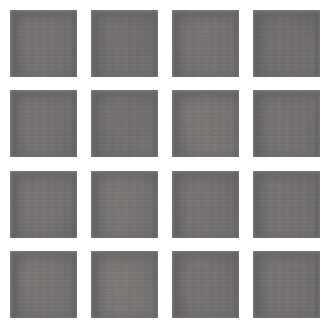

Epoch 2, Gen Loss: 5.3163, Disc Loss: 0.0716


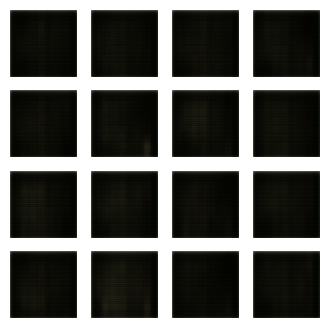

Epoch 3, Gen Loss: 4.6792, Disc Loss: 0.1105


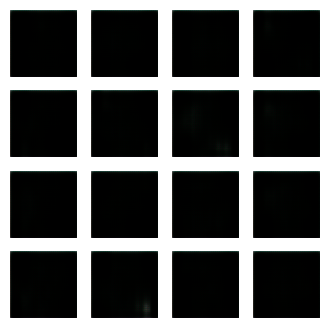

Epoch 4, Gen Loss: 3.8513, Disc Loss: 0.2338


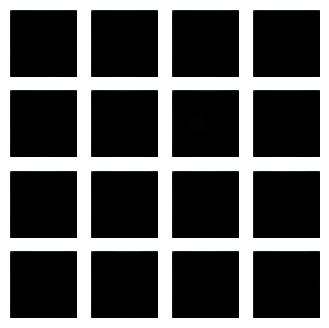

Epoch 5, Gen Loss: 2.6435, Disc Loss: 1.3867


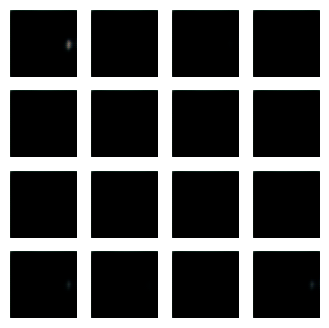

Epoch 6, Gen Loss: 2.7476, Disc Loss: 0.4989


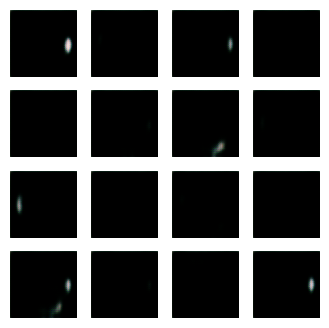

Epoch 7, Gen Loss: 1.8723, Disc Loss: 0.6725


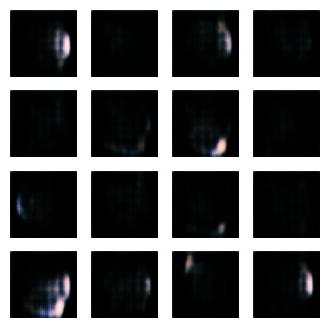

Epoch 8, Gen Loss: 2.5610, Disc Loss: 0.5727


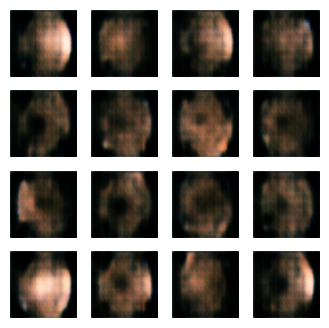

Epoch 9, Gen Loss: 1.1941, Disc Loss: 0.7382


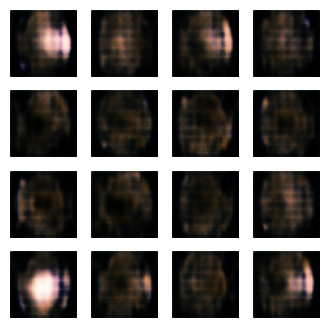

Epoch 10, Gen Loss: 2.1030, Disc Loss: 0.8770


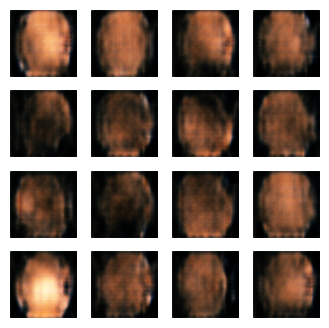

Epoch 11, Gen Loss: 0.8841, Disc Loss: 1.4769


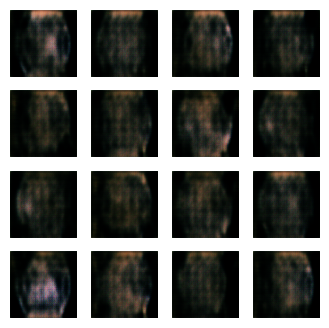

Epoch 12, Gen Loss: 0.8655, Disc Loss: 1.4592


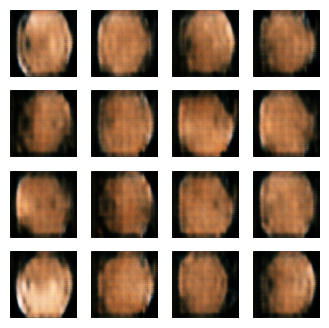

Epoch 13, Gen Loss: 1.0721, Disc Loss: 0.8501


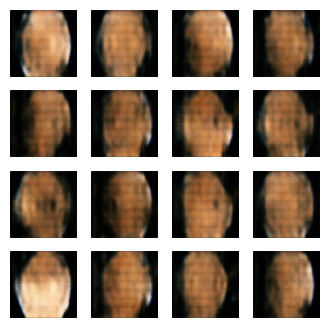

Epoch 14, Gen Loss: 1.1588, Disc Loss: 0.7988


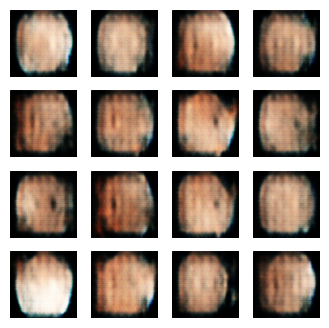

Epoch 15, Gen Loss: 0.7796, Disc Loss: 1.3592


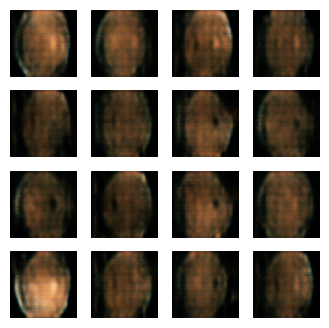

Epoch 16, Gen Loss: 1.0170, Disc Loss: 1.0188


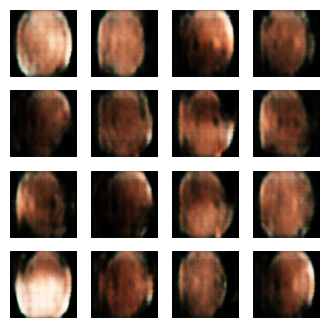

Epoch 17, Gen Loss: 1.1741, Disc Loss: 0.7825


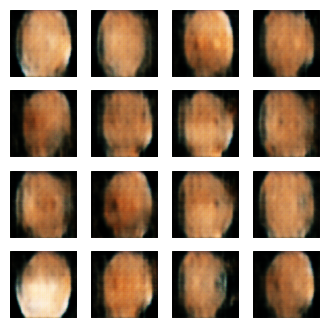

Epoch 18, Gen Loss: 1.0509, Disc Loss: 0.9663


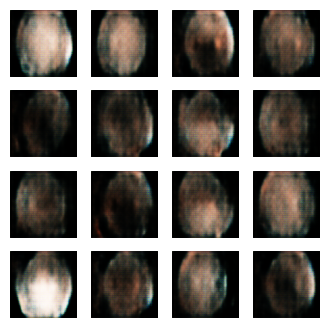

Epoch 19, Gen Loss: 1.9504, Disc Loss: 1.3385


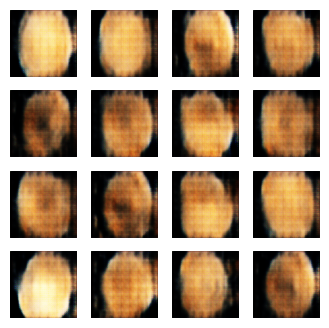

Epoch 20, Gen Loss: 1.2121, Disc Loss: 1.2723


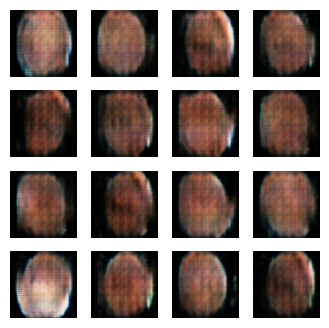

Epoch 21, Gen Loss: 1.1279, Disc Loss: 0.8834


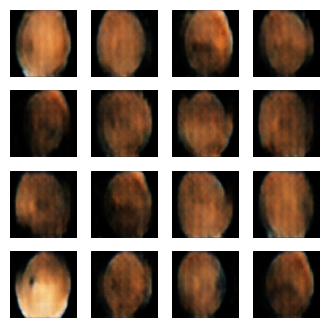

Epoch 22, Gen Loss: 0.9512, Disc Loss: 0.8733


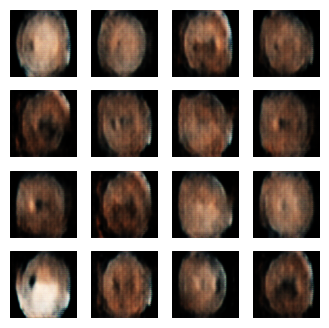

Epoch 23, Gen Loss: 0.8926, Disc Loss: 1.0043


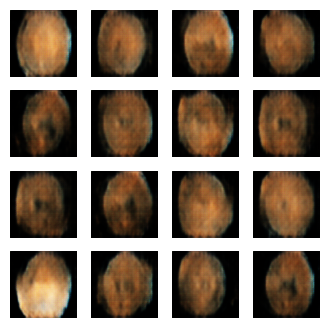

Epoch 24, Gen Loss: 1.4432, Disc Loss: 0.9237


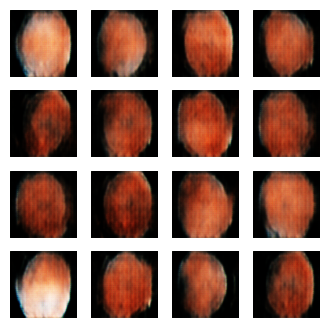

Epoch 25, Gen Loss: 1.2900, Disc Loss: 0.9019


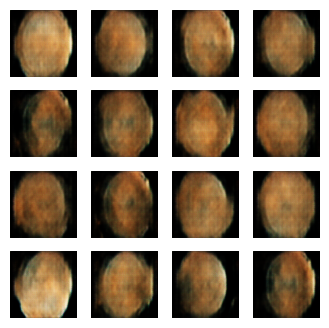

Epoch 26, Gen Loss: 1.2481, Disc Loss: 0.6542


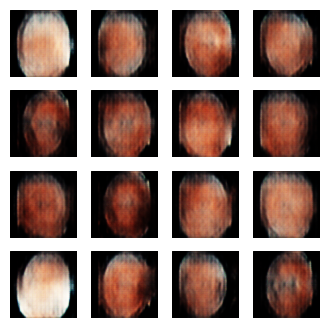

Epoch 27, Gen Loss: 0.9684, Disc Loss: 1.0367


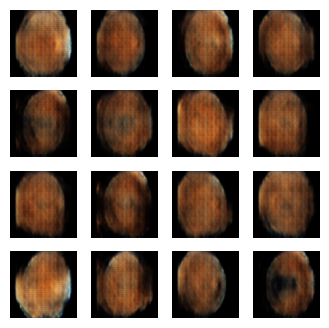

Epoch 28, Gen Loss: 1.3268, Disc Loss: 0.9335


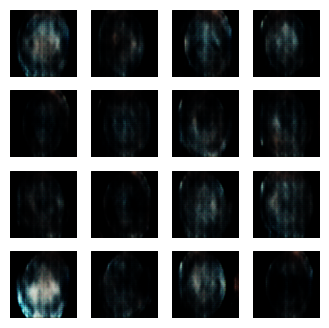

Epoch 29, Gen Loss: 1.1692, Disc Loss: 0.9333


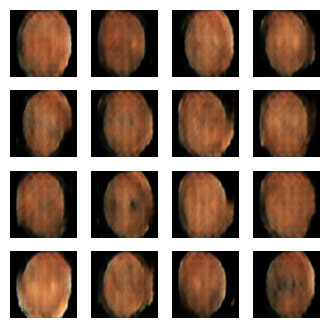

Epoch 30, Gen Loss: 1.3160, Disc Loss: 0.7061


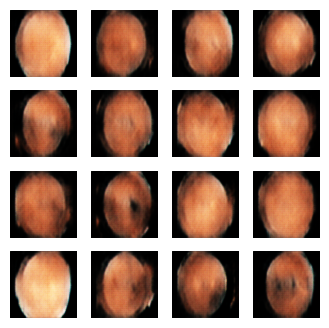

Epoch 31, Gen Loss: 1.1739, Disc Loss: 0.9215


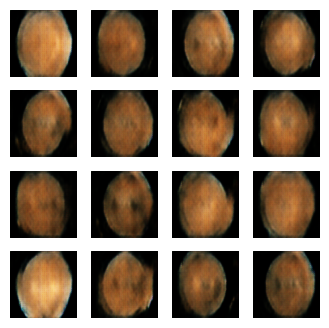

Epoch 32, Gen Loss: 1.6121, Disc Loss: 0.9058


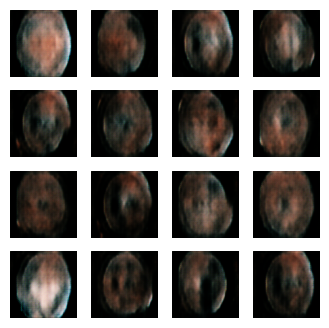

Epoch 33, Gen Loss: 1.4395, Disc Loss: 0.5989


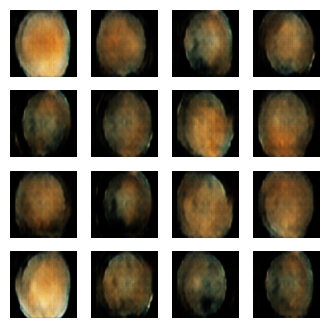

Epoch 34, Gen Loss: 1.7143, Disc Loss: 0.6615


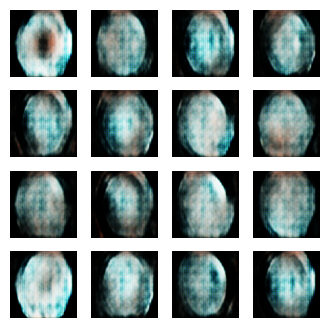

Epoch 35, Gen Loss: 1.3504, Disc Loss: 0.7140


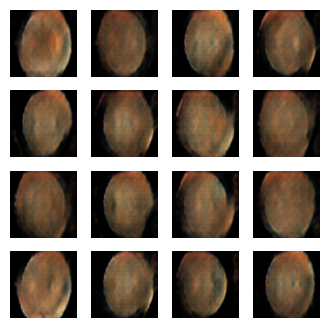

Epoch 36, Gen Loss: 1.1507, Disc Loss: 0.7492


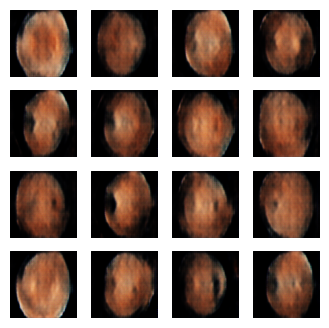

Epoch 37, Gen Loss: 1.4681, Disc Loss: 0.6831


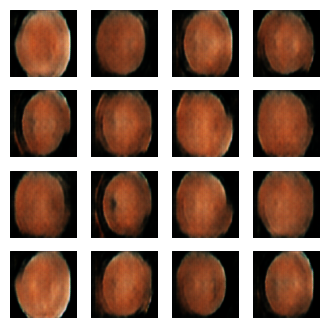

Epoch 38, Gen Loss: 1.3649, Disc Loss: 0.9345


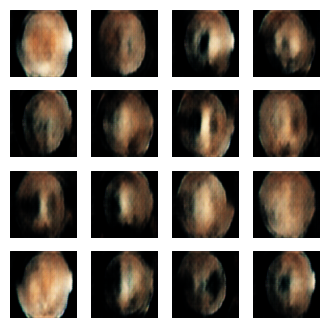

Epoch 39, Gen Loss: 1.7619, Disc Loss: 0.9164


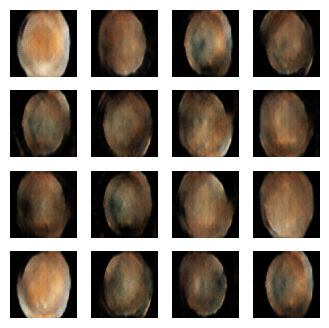

Epoch 40, Gen Loss: 1.0613, Disc Loss: 1.8268


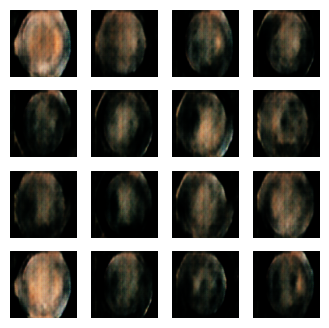

Epoch 41, Gen Loss: 1.7995, Disc Loss: 1.4900


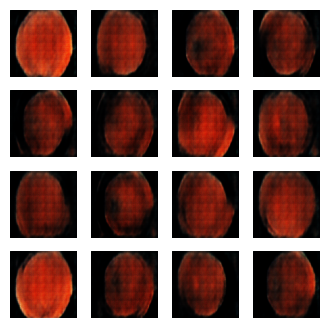

Epoch 42, Gen Loss: 0.8866, Disc Loss: 0.9529


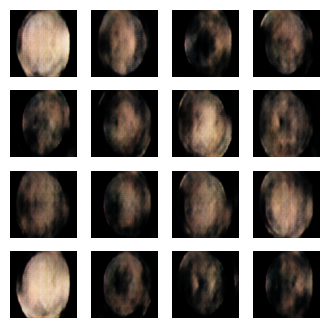

Epoch 43, Gen Loss: 1.5876, Disc Loss: 1.8778


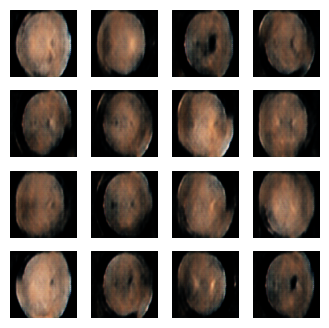

Epoch 44, Gen Loss: 1.3158, Disc Loss: 0.8498


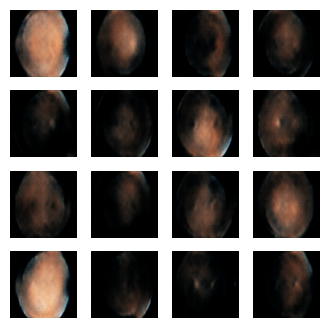

Epoch 45, Gen Loss: 1.0516, Disc Loss: 0.9911


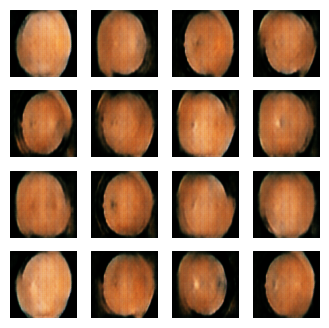

Epoch 46, Gen Loss: 1.3216, Disc Loss: 0.7993


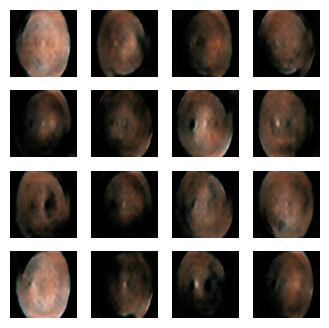

Epoch 47, Gen Loss: 0.8536, Disc Loss: 1.1401


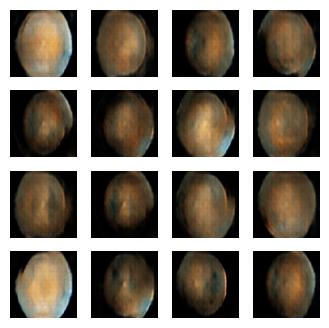

Epoch 48, Gen Loss: 1.2255, Disc Loss: 1.0183


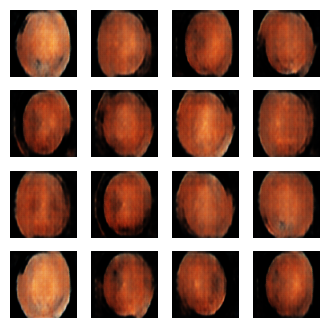

Epoch 49, Gen Loss: 1.0800, Disc Loss: 1.2626


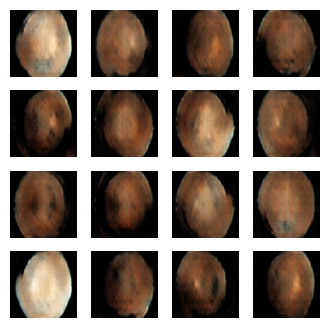

Epoch 50, Gen Loss: 1.0940, Disc Loss: 1.3295


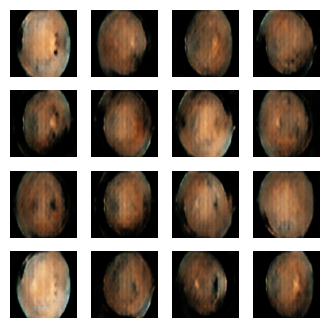

Epoch 51, Gen Loss: 1.2972, Disc Loss: 0.7452


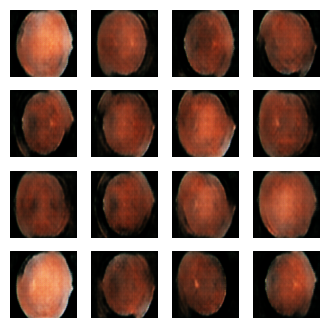

KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt

EPOCHS = 200  # Train longer for better quality
NOISE_DIM = 100
NUM_EXAMPLES_TO_GENERATE = 16

seed = tf.random.normal([NUM_EXAMPLES_TO_GENERATE, NOISE_DIM])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    predictions = (predictions + 1)/2
    fig = plt.figure(figsize=(4,4))
    for i in range(predictions.shape[0]):
        plt.subplot(4,4,i+1)
        plt.imshow(predictions[i])
        plt.axis('off')
    plt.show()

def train(dataset, epochs):
    for epoch in range(epochs):
        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)

        with summary_writer.as_default():
            tf.summary.scalar('gen_loss', gen_loss, step=epoch)
            tf.summary.scalar('disc_loss', disc_loss, step=epoch)

        print(f"Epoch {epoch+1}, Gen Loss: {gen_loss:.4f}, Disc Loss: {disc_loss:.4f}")
        generate_and_save_images(generator, epoch+1, seed)

train(dataset, EPOCHS)


In [ ]:
from tensorflow.keras.models import load_model

# Path to your saved generator
generator_path = '/content/drive/MyDrive/retina_gan/generator.keras'

# Load generator
generator = load_model(generator_path)
print("Generator loaded successfully!")


Generator loaded successfully!


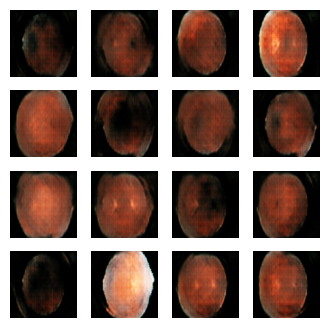

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Number of images to generate
NUM_IMAGES = 16
NOISE_DIM = 100

# Generate random noise
noise = tf.random.normal([NUM_IMAGES, NOISE_DIM])

# Generate images
generated_images = generator(noise, training=False)
generated_images = (generated_images + 1) / 2.0  # Rescale from [-1,1] to [0,1]

# Display images in a grid
plt.figure(figsize=(4,4))
for i in range(NUM_IMAGES):
    plt.subplot(4,4,i+1)
    plt.imshow(generated_images[i])
    plt.axis('off')
plt.show()
